In [1]:
# Plot test results from ssp245

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from cmcrameri import cm 
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
import xarray as xr

from fast_o3_iv import utils, plots, metrics
from fast_o3_iv import bias_correction as bc
from fast_o3_iv import attributable_fraction as af
from fast_o3_iv.modeling.train import DatasetConfig

In [4]:
config_ssp245 = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'ssp245',
            variable_setname = 'setC',
            year_range = range(2015,2055)
        )


In [5]:
file_path = bc.return_osdma8_bc_path("inference", config_ssp245, "GPR-local")
osdma8 = xr.open_dataset(file_path)

In [6]:
ens_mean_clm = metrics.calc_ensemble_mean_clim(osdma8)
resid_std = metrics.calc_resid_standard_deviation(osdma8)
pq90 = metrics.calc_prob_exceed_true_q90(osdma8, q=0.90)
emd_to_noise = metrics.calc_emd_to_noise(osdma8)

In [7]:
clim_true  = ens_mean_clm['y_true']
clim_pred  = ens_mean_clm['y_pred']
std_true = resid_std['y_true']
std_pred = resid_std['y_pred']

clim_diff  = clim_pred - clim_true
std_diff = std_pred - std_true

pgtq90_true  = pq90['prob_true_exceed_true_q90']
pgtq90_pred  = pq90['prob_pred_exceed_true_q90']
pgtq90_diff  = pgtq90_pred - pgtq90_true

emdtonoise = emd_to_noise['emd_to_noise']


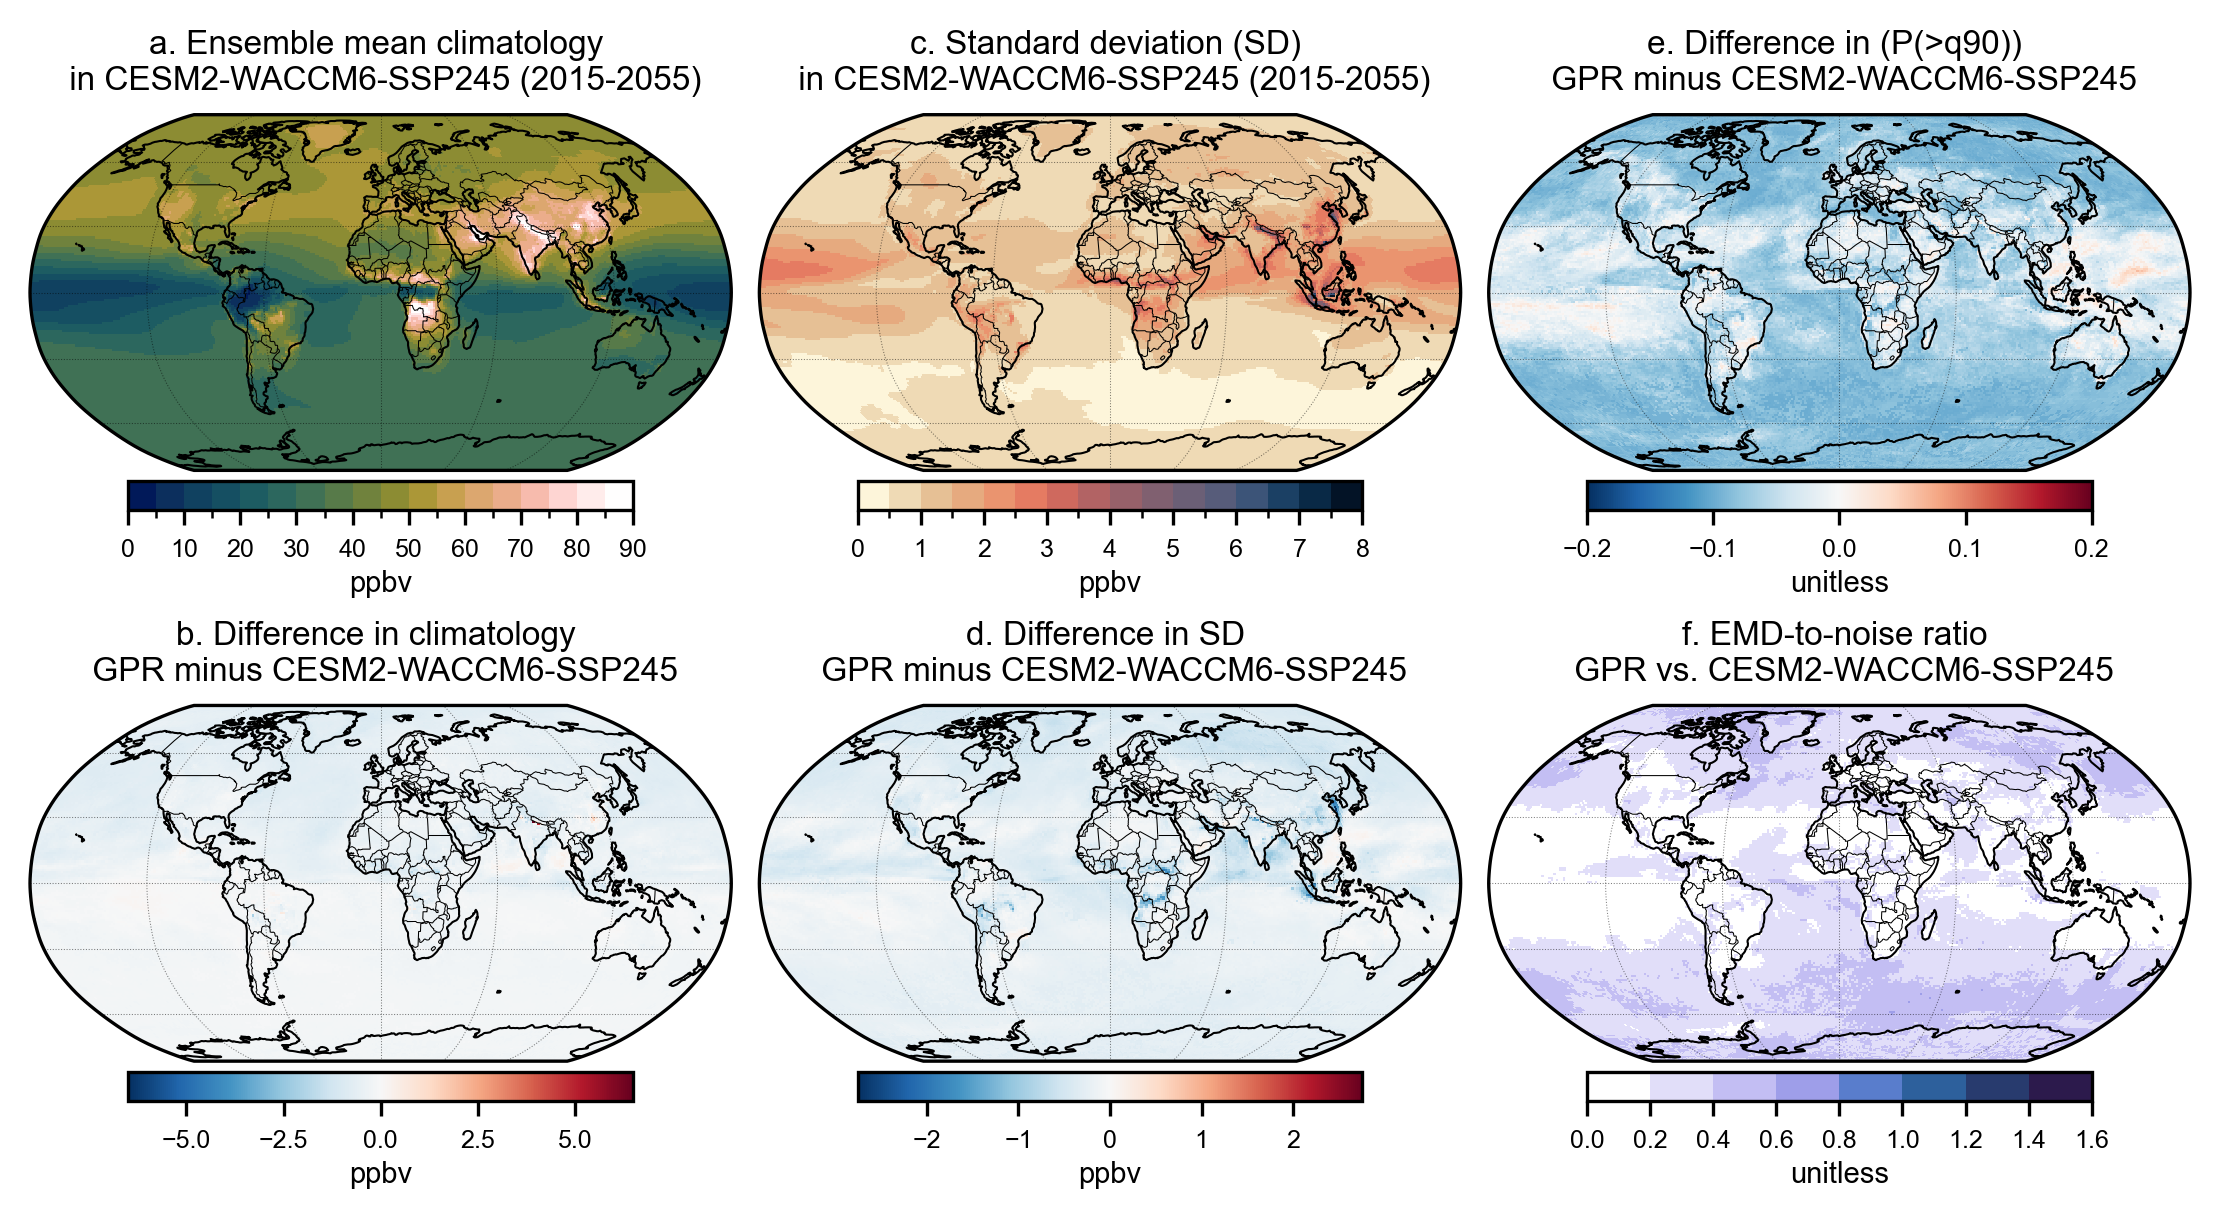

In [8]:
utils.set_matplotlib_font("Arial")
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
color = 'black'

mpl.rcParams.update({
    'axes.edgecolor': color,      
    'xtick.color': color,         
    'ytick.color': color,         
    'xtick.labelcolor': color,    
    'ytick.labelcolor': color,    
    'grid.color': color,          
    'axes.labelcolor': color,    
    'axes.titlecolor': color,    
})

mpl.rcParams.update({
    'font.size': 8, 
    'axes.titlesize': 10, 
    'axes.labelsize': 10,
    'xtick.labelsize': 8, 
    'ytick.labelsize': 8, 
    'legend.fontsize': 8,
    'figure.titlesize': 10
})

def style_map(ax):
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl

def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    # y < 0 pushes the colorbar below the axis
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2)  # label close
    return cb

fig_width_in = 9
fig_height_in = 4

fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(
    2, 3,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.60, wspace=0.04
)        

proj = ccrs.Robinson(central_longitude=0)
# Column 1
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[1, 0], projection=proj)

# Column 2
ax3 = fig.add_subplot(gs1[0, 1], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

# Column 3
ax5 = fig.add_subplot(gs1[0, 2], projection=proj)
ax6 = fig.add_subplot(gs1[1, 2], projection=proj)

axes = [ax1, ax2, ax3, ax4, ax5, ax6]

titles= ["a. Ensemble mean climatology \n in CESM2-WACCM6-SSP245 (2015-2055)", 
         "b. Difference in climatology \n GPR minus CESM2-WACCM6-SSP245", 
         "c. Standard deviation (SD) \n in CESM2-WACCM6-SSP245 (2015-2055)", 
         "d. Difference in SD \n GPR minus CESM2-WACCM6-SSP245",
         "e. Difference in (P(>q90)) \n GPR minus CESM2-WACCM6-SSP245", 
         "f. EMD-to-noise ratio \n GPR vs. CESM2-WACCM6-SSP245", 
         ]


for ax, t in zip(axes, titles):
    ax.set_title(t, color="black", fontsize=8)
    style_map(ax)

#---------------# climatology 1 #---------------#
vmax = 90
vmin = 0
step = 5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.batlowW
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m1 = clim_true.plot.pcolormesh(
    ax=ax1, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax1, m1, label="ppbv")

#---------------# climatology diff #---------------#
m2 = clim_diff.plot.pcolormesh(
    ax=ax2, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax2, m2, label="ppbv")



#---------------# standard deviation #---------------#
vmax = 8
vmin = 0
step = 0.5
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.lipari_r
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m3 = std_true.plot.pcolormesh(
    ax=ax3, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax3, m3, label="ppbv")

#---------------# sd diff #---------------#
m4 = std_diff.plot.pcolormesh(
    ax=ax4, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax4, m4, label="ppbv")

#---------------# pq90 diff #---------------#
m5 = pgtq90_diff.plot.pcolormesh(
    ax=ax5, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", #norm=norm,
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()
    vmin=-0.20, vmax=0.20,

)
add_panel_cbar(fig, ax5, m5, label="unitless")

#---------------# emd-to-noise diff #---------------#

vmax = 1.6
vmin = 0
step = 0.2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1
base = cm.devon_r
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)


m6 = emdtonoise.plot.pcolormesh(
    ax=ax6, transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm,
    #vmin=0, vmax=1, 
    add_colorbar=False, rasterized=True,
    add_labels=False,   # to keep  ax.set_title()

)
add_panel_cbar(fig, ax6, m6, label="unitless")
